# Credit Card Fraud Detection

Card fraud is rare (about 1 in 600 transactions here) and every missed case costs money, while every false alarm costs a review and an annoyed customer. This notebook builds and compares three detectors on 284,807 real European card transactions and picks a decision threshold by expected cost, not by accuracy.

Models:
- **Logistic regression** with class weights (baseline)
- **XGBoost** with `scale_pos_weight`
- **Isolation Forest** (unsupervised anomaly detection, no labels used in training)

Evaluation uses a **time-based split**: train on the first 80% of the two days, test on the last 20%. A random split would leak future patterns into training.

In [1]:
import zipfile
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, classification_report)
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Data

The [ULB credit card fraud dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud): two days of transactions from September 2013. Features `V1`–`V28` are PCA components (the original fields are confidential), plus `Time` (seconds since the first transaction) and `Amount`. A copy is hosted on GitHub, so the notebook downloads it directly.

In [2]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/creditcard.csv.zip"
cols = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]
LOCAL = Path("creditcard.csv.zip")
if not LOCAL.exists():
    urlretrieve(URL, LOCAL)          # about 69 MB, downloaded once
with zipfile.ZipFile(LOCAL) as z:
    with z.open("creditcard.csv") as f:
        df = pd.read_csv(f, header=None, names=cols)
print(df.shape)
df["Class"].value_counts().to_frame("count").assign(share=lambda d: (d["count"] / len(df)).round(5))

(284807, 31)


,count,share
Class,,
0,284315,0.99827
1,492,0.00173


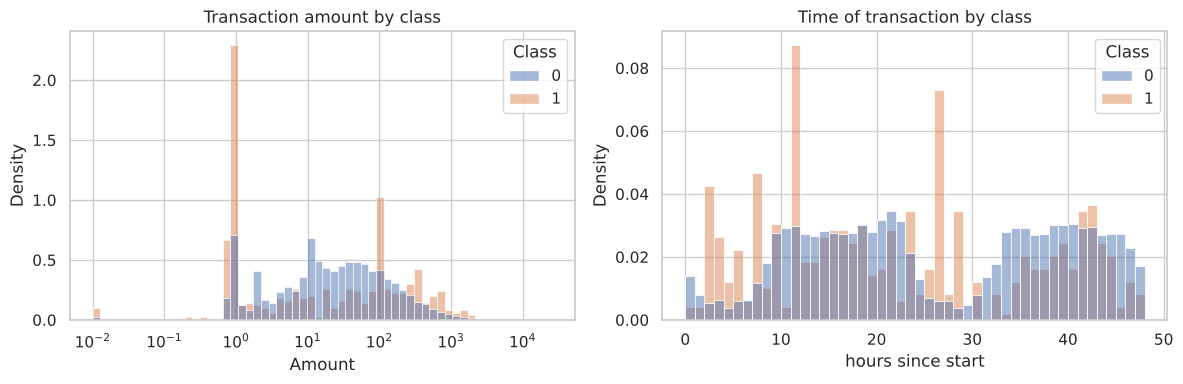

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="Amount", hue="Class", bins=60, log_scale=(True, False), stat="density",
             common_norm=False, ax=ax[0])
ax[0].set_title("Transaction amount by class")
sns.histplot(data=df, x=df["Time"] / 3600, hue="Class", bins=48, stat="density", common_norm=False, ax=ax[1])
ax[1].set_xlabel("hours since start"); ax[1].set_title("Time of transaction by class")
plt.tight_layout(); plt.savefig("images/eda.png", dpi=120); plt.show()

Legitimate traffic drops overnight while fraud does not, so fraud makes up a much larger share of night-time transactions. I add hour of day as a feature. Fraud amounts also show a sharp spike at about $1, a pattern consistent with card testing (small charges to check a stolen card works).

In [4]:
df["hour"] = (df["Time"] // 3600) % 24
df["log_amount"] = np.log1p(df["Amount"])
features = [f"V{i}" for i in range(1, 29)] + ["log_amount", "hour"]

df = df.sort_values("Time")
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut], df.iloc[cut:]
X_train, y_train = train[features], train["Class"]
X_test, y_test = test[features], test["Class"]
print(f"train: {len(train):,} rows, {y_train.sum()} frauds | test: {len(test):,} rows, {y_test.sum()} frauds")

train: 227,845 rows, 417 frauds | test: 56,962 rows, 75 frauds


## 2. Models

Accuracy is useless here: predicting "not fraud" for everything scores 99.8%. The main metric is **PR-AUC** (average precision), which focuses on how well the model ranks the rare fraud cases.

In [5]:
neg, pos = np.bincount(y_train)
models = {
    "Logistic regression": make_pipeline(StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=2000)),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=neg / pos, eval_metric="aucpr",
        random_state=RANDOM_STATE, n_jobs=-1),
}
scores = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    scores[name] = m.predict_proba(X_test)[:, 1]

iso = IsolationForest(n_estimators=300, contamination="auto", random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X_train)                      # labels not used
scores["Isolation Forest"] = -iso.score_samples(X_test)   # higher = more anomalous

summary = pd.DataFrame({name: {"PR-AUC": average_precision_score(y_test, s),
                               "ROC-AUC": roc_auc_score(y_test, s)} for name, s in scores.items()}).T.round(3)
summary

,PR-AUC,ROC-AUC
Logistic regression,0.759,0.987
XGBoost,0.796,0.986
Isolation Forest,0.047,0.951


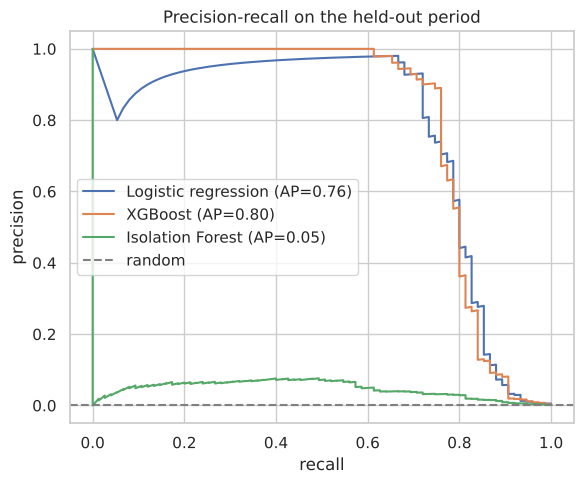

In [6]:
plt.figure(figsize=(6, 5))
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    plt.plot(r, p, label=f"{name} (AP={average_precision_score(y_test, s):.2f})")
plt.axhline(y_test.mean(), ls="--", c="grey", label="random")
plt.xlabel("recall"); plt.ylabel("precision"); plt.title("Precision-recall on the held-out period")
plt.legend(); plt.tight_layout(); plt.savefig("images/pr_curves.png", dpi=120); plt.show()

In [7]:
# Share of all test-period fraud caught if analysts review the top 1% highest-scored transactions
k = int(len(y_test) * 0.01)
pd.Series({name: y_test.values[np.argsort(-sc)[:k]].sum() / y_test.sum() for name, sc in scores.items()},
          name="fraud caught in top 1%").round(3).to_frame()

,fraud caught in top 1%
Logistic regression,0.867
XGBoost,0.867
Isolation Forest,0.520


Isolation Forest, which never saw a label, still ranks fraud far better than chance. That matters in practice, because new fraud patterns arrive before anyone has labeled them. The supervised models are much stronger once labels exist, and XGBoost is the best of the three.

## 3. Choosing a threshold by cost

A model outputs a score; the business needs a yes/no decision. Assumptions for this example:
- A **missed fraud** costs the transaction amount (chargeback).
- A **false alarm** costs **$10** (analyst review plus customer friction).

The best threshold is the one with the lowest total cost on the test period.

cost with no model (all fraud missed): $7,729
cost at threshold 0.50:               $2,878
best threshold 0.94:              $2,708


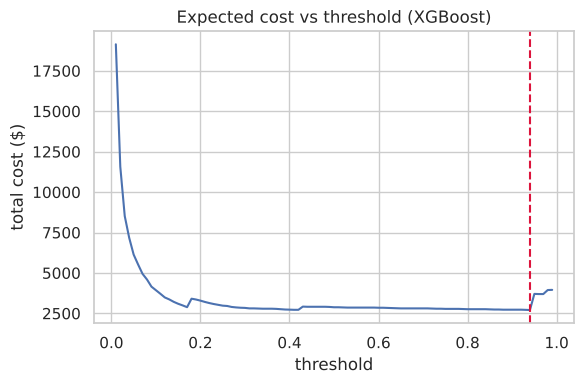

In [8]:
REVIEW_COST = 10
amount = test["Amount"].values
s = scores["XGBoost"]

def total_cost(th):
    flag = s >= th
    missed = (~flag) & (y_test.values == 1)
    false_alarm = flag & (y_test.values == 0)
    return amount[missed].sum() + REVIEW_COST * false_alarm.sum()

thresholds = np.linspace(0.01, 0.99, 99)
costs = np.array([total_cost(t) for t in thresholds])
best_th = thresholds[costs.argmin()]
no_model = amount[y_test.values == 1].sum()
print(f"cost with no model (all fraud missed): ${no_model:,.0f}")
print(f"cost at threshold 0.50:               ${total_cost(0.5):,.0f}")
print(f"best threshold {best_th:.2f}:              ${costs.min():,.0f}")

plt.figure(figsize=(6, 4))
plt.plot(thresholds, costs); plt.axvline(best_th, ls="--", c="crimson")
plt.xlabel("threshold"); plt.ylabel("total cost ($)"); plt.title("Expected cost vs threshold (XGBoost)")
plt.tight_layout(); plt.savefig("images/cost_curve.png", dpi=120); plt.show()

              precision    recall  f1-score   support

       legit      1.000     1.000     1.000     56887
       fraud      0.891     0.760     0.820        75

    accuracy                          1.000     56962
   macro avg      0.945     0.880     0.910     56962
weighted avg      1.000     1.000     1.000     56962



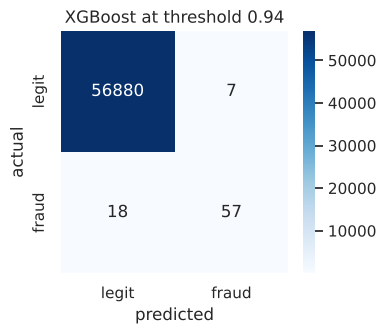

In [9]:
pred = (s >= best_th).astype(int)
cm = confusion_matrix(y_test, pred)
print(classification_report(y_test, pred, target_names=["legit", "fraud"], digits=3))
plt.figure(figsize=(4, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["legit", "fraud"], yticklabels=["legit", "fraud"])
plt.xlabel("predicted"); plt.ylabel("actual"); plt.title(f"XGBoost at threshold {best_th:.2f}")
plt.tight_layout(); plt.savefig("images/confusion_matrix.png", dpi=120); plt.show()

## 4. What drives the model?

SHAP values show how much each feature pushes a transaction's score up or down. The PCA features have no business names, but this still tells an analyst which signals to monitor for drift.

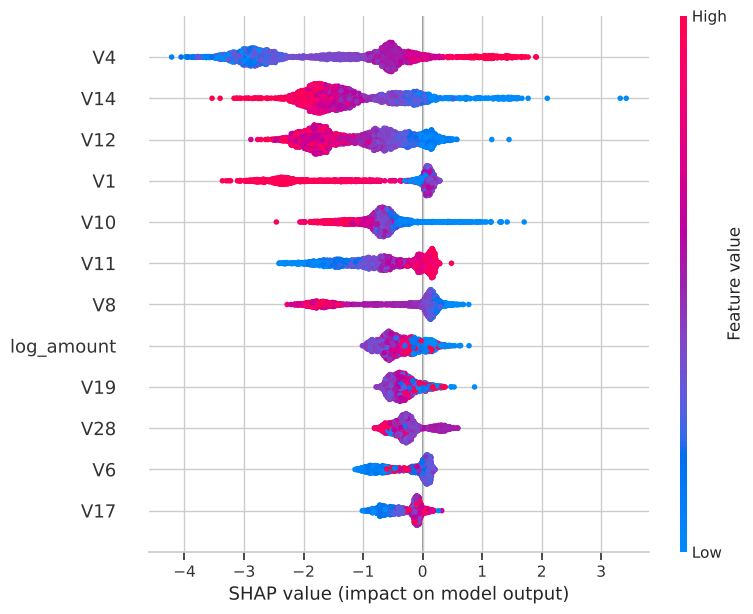

In [10]:
sample = X_test.sample(3000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(models["XGBoost"])
sv = explainer.shap_values(sample)
shap.summary_plot(sv, sample, max_display=12, show=False)
plt.tight_layout(); plt.savefig("images/shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()

## Takeaways

- XGBoost gives the best ranking of fraud on a later time period it never trained on.
- Isolation Forest, trained with no labels, still puts about half of all fraud in its top 1% of scores (ROC-AUC 0.95), though its precision is low. It works best as an early-warning layer for new attack patterns, not as the main detector.
- Picking the threshold by expected cost, rather than the default 0.5, changes the trade-off between missed fraud and review workload. The cost assumptions should come from the fraud operations team.

**Next steps:** add velocity features (transactions per card per hour) once card IDs are available, retrain on a rolling window, and monitor score drift week to week.